In [ ]:
import os
from google.colab import userdata

# Retrieve the secret (make sure the name exactly matches what you named it in the sidebar)
kaggle_token = userdata.get('KAGGLE_API_TOKEN')

# Set it as an environment variable so Kaggle can authenticate you
os.environ["KAGGLE_API_TOKEN"] = kaggle_token

In [ ]:
!kaggle datasets download -d humansintheloop/semantic-segmentation-of-aerial-imagery --unzip


In [ ]:
"""
The dataset consists of aerial imagery of Dubai obtained by MBRSC satellites and annotated with pixel-wise semantic segmentation in 6 classes. The total volume of the dataset is 72 images grouped into 6 larger tiles. The classes are:

Building: #3C1098
Land (unpaved area): #8429F6
Road: #6EC1E4
Vegetation: #FEDD3A
Water: #E2A929
Unlabeled: #9B9B9B

Use patchify....
Tile 1: 797 x 644 --> 768 x 512 --> 6
Tile 2: 509 x 544 --> 512 x 256 --> 2
Tile 3: 682 x 658 --> 512 x 512  --> 4
Tile 4: 1099 x 846 --> 1024 x 768 --> 12
Tile 5: 1126 x 1058 --> 1024 x 1024 --> 16
Tile 6: 859 x 838 --> 768 x 768 --> 9
Tile 7: 1817 x 2061 --> 1792 x 2048 --> 56
Tile 8: 2149 x 1479 --> 1280 x 2048 --> 40
Total 9 images in each folder * (145 patches) = 1305
Total 1305 patches of size 256x256

"""


In [ ]:
!pip install -q patchify --no-deps
!pip install -q segmentation-models

In [ ]:
import os # for intercaing with operating system, like setting env, file paths and dir etc..
import cv2 # imports OpenCV for computer vision and ML (image and video processing)
import numpy as np # for handling arrays and matrices

from matplotlib import pyplot as plt # for plotting graphs and visualizations
from patchify import patchify # used to break down large images into smaller, overlapping or non-overlapping patches
from PIL import Image # (PIL- Python Imaging library), provides image manipulation like resizing, rotating and color adjustments

os.environ['SM_FRAMEWORK'] = 'tf.keras' # Set this before importing segmentation_models, as it explicitly tells the library to use tf.keras as it's backend and it resolves compatibility issues with diff. keras versions
import segmentation_models as sm #This library provides a collection of popular segmentation models (like U-Net, FPN, LinkNet, PSPNet) pre-built with various backbones, making it easier to implement semantic, instance, or panoptic segmentation tasks.
from tensorflow.keras.metrics import MeanIoU # MEan Intersection over Union which measures avg. overlap betwen the predicted seegmentation and the ground truth mask

from sklearn.preprocessing import MinMaxScaler, StandardScaler
#MinMaxScalar scales and transform features to a given range 0 to 1
#Standard scalar used to preprocess input data for ML models

scaler = MinMaxScaler()

root_directory = 'Semantic segmentation dataset/'

patch_size = 256

Segmentation Models: using `tf.keras` framework.


Now patchifying image: Semantic segmentation dataset/Tile 2/images/image_part_001.jpg
Now patchifying image: Semantic segmentation dataset/Tile 2/images/image_part_002.jpg
Now patchifying image: Semantic segmentation dataset/Tile 2/images/image_part_003.jpg
Now patchifying image: Semantic segmentation dataset/Tile 2/images/image_part_004.jpg
Now patchifying image: Semantic segmentation dataset/Tile 2/images/image_part_005.jpg
Now patchifying image: Semantic segmentation dataset/Tile 2/images/image_part_006.jpg
Now patchifying image: Semantic segmentation dataset/Tile 2/images/image_part_007.jpg
Now patchifying image: Semantic segmentation dataset/Tile 2/images/image_part_008.jpg
Now patchifying image: Semantic segmentation dataset/Tile 2/images/image_part_009.jpg
Now patchifying image: Semantic segmentation dataset/Tile 1/images/image_part_001.jpg
Now patchifying image: Semantic segmentation dataset/Tile 1/images/image_part_002.jpg
Now patchifying image: Semantic segmentation dataset/T

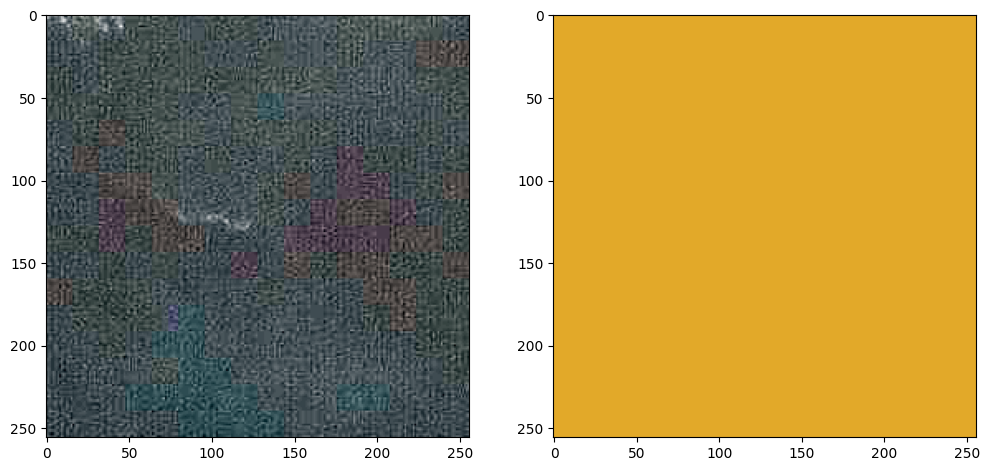

In [ ]:
#Read images from repsective 'images' subdirectory
#As all images are of different size we have 2 options, either resize or crop
#But, some images are too large and some small. Resizing will change the size of real objects.
#Therefore, we will crop them to a nearest size divisible by 256 and then
#divide all images into patches of 256x256x3.
image_dataset = []
for path, subdirs, files in os.walk(root_directory): #path holds the current folder name, subdirs is a list of subfolders inside it, and files is a list of files inside it.
    #print(path)
    dirname = path.split(os.path.sep)[-1]
    if dirname == 'images':   #Find all 'images' directories
        images = os.listdir(path)  #List of all image names in this subdirectory
        images.sort()
        for i, image_name in enumerate(images):  #Index number and file name
            if image_name.endswith(".jpg"):   #Only read jpg images...

                image = cv2.imread(path+"/"+image_name, 1)  #Read each image as BGR(3color channels) and here we converting out images into numPy arrays
                SIZE_X = (image.shape[1]//patch_size)*patch_size #Nearest size divisible by our patch size
                SIZE_Y = (image.shape[0]//patch_size)*patch_size #Nearest size divisible by our patch size
                image = Image.fromarray(image) #Converts the image from a NumPy array format into a PIL (Python Imaging Library) Image object.
                #As NumPy dosn't have .crop() so we need to convert it to PIL for cropping the patches and then back to numPy
                image = image.crop((0 ,0, SIZE_X, SIZE_Y))  #Crop from top left corner
                #image = image.resize((SIZE_X, SIZE_Y))  #Try not to resize for semantic segmentation
                image = np.array(image)  #Converts the PIL Image object back into a NumPy array.

                #Extract patches from each image
                print("Now patchifying image:", path+"/"+image_name)
                patches_img = patchify(image, (patch_size, patch_size, 3), step=patch_size)  #Step=256 for 256 patches means no overlap

                for i in range(patches_img.shape[0]):
                    for j in range(patches_img.shape[1]):
#Iterates through every row (i) and column (j) of the patch grid generated by patchify. patches_img.shape[0] gives the total number of patches vertically,
#and patches_img.shape[1] gives the number horizontally.

                        single_patch_img = patches_img[i,j,:,:] #Pulls out a single patch located at grid position (i, j)

                        #Use minmaxscaler instead of just dividing by 255.
                        single_patch_img = scaler.fit_transform(single_patch_img.reshape(-1, single_patch_img.shape[-1])).reshape(single_patch_img.shape)

                        #single_patch_img = (single_patch_img.astype('float32')) / 255.
                        single_patch_img = single_patch_img[0] #Drop the extra unecessary dimension that patchify adds.
                        image_dataset.append(single_patch_img) #Appends the cleaned, normalized 256 x 256 x 3 patch to the list image_dataset




 #Now do the same as above for masks
 #For this specific dataset we could have added masks to the above code as masks have extension png
mask_dataset = []
for path, subdirs, files in os.walk(root_directory):
    #print(path)
    dirname = path.split(os.path.sep)[-1]
    if dirname == 'masks':   #Find all 'images' directories
        masks = os.listdir(path)  #List of all image names in this subdirectory
        masks.sort()
        for i, mask_name in enumerate(masks):
            if mask_name.endswith(".png"):   #Only read png images... (masks in this dataset)

                mask = cv2.imread(path+"/"+mask_name, 1)  #Read each image as Grey (or color but remember to map each color to an integer)
                mask = cv2.cvtColor(mask,cv2.COLOR_BGR2RGB)
                SIZE_X = (mask.shape[1]//patch_size)*patch_size #Nearest size divisible by our patch size
                SIZE_Y = (mask.shape[0]//patch_size)*patch_size #Nearest size divisible by our patch size
                mask = Image.fromarray(mask)
                mask = mask.crop((0 ,0, SIZE_X, SIZE_Y))  #Crop from top left corner
                #mask = mask.resize((SIZE_X, SIZE_Y))  #Try not to resize for semantic segmentation
                mask = np.array(mask)

                #Extract patches from each image
                print("Now patchifying mask:", path+"/"+mask_name)
                patches_mask = patchify(mask, (patch_size, patch_size, 3), step=patch_size)  #Step=256 for 256 patches means no overlap

                for i in range(patches_mask.shape[0]):
                    for j in range(patches_mask.shape[1]):

                        single_patch_mask = patches_mask[i,j,:,:]
                        #single_patch_img = (single_patch_img.astype('float32')) / 255. #No need to scale masks, but you can do it if you want
                        single_patch_mask = single_patch_mask[0] #Drop the extra unecessary dimension that patchify adds.
                        mask_dataset.append(single_patch_mask)

image_dataset = np.array(image_dataset)
mask_dataset =  np.array(mask_dataset)

#Sanity check, view few mages
import random # allow us to select random number
import numpy as np
image_number = random.randint(0, len(image_dataset)) #Generates a random integer index between 0 and the total number of patches in image_dataset
plt.figure(figsize=(12, 6)) # Creates a new Matplotlib plot window with a width of 12 inches and a height of 6 inches.
plt.subplot(121) # Divides the figure window into a grid layout. The shorthand 121 means: 1 row , 2 columns,1st plot position (the left side of the window).
plt.imshow(np.reshape(image_dataset[image_number], (patch_size, patch_size, 3)))
# image_dataset[image_number]: Pulls the randomly selected image patch from the array.
#np.reshape(..., (patch_size, patch_size, 3)): Explicitly reshapes the selected array to ensure it is in the standard 3D dimensions (256, 256, 3) for rendering.
#plt.imshow(...): Displays the pixel data as a visual image on the left subplot.
plt.subplot(122) #Switches the plotting target to the 2nd position (the right side) of the 1-row, 2-column grid
plt.imshow(np.reshape(mask_dataset[image_number], (patch_size, patch_size, 3))) # ground truth mask tile at the exact same index as the image above.
plt.show()

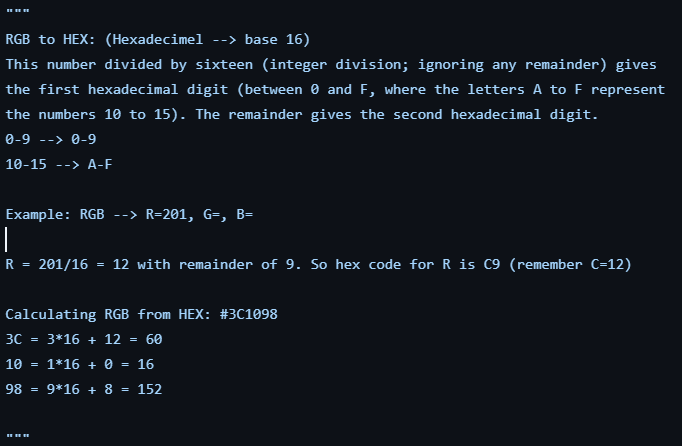

60
Unique labels in label dataset are:  [0 1 2 3 4 5]


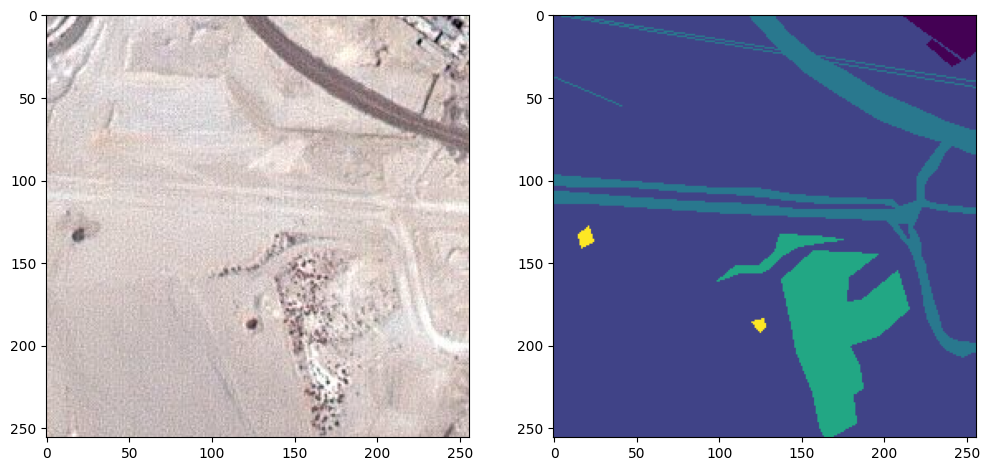

In [ ]:
###########################################################################
"""
RGB to HEX: (Hexadecimel --> base 16)
This number divided by sixteen (integer division; ignoring any remainder) gives
the first hexadecimal digit (between 0 and F, where the letters A to F represent
the numbers 10 to 15). The remainder gives the second hexadecimal digit.
0-9 --> 0-9
10-15 --> A-F

Example: RGB --> R=201, G=, B=

R = 201/16 = 12 with remainder of 9. So hex code for R is C9 (remember C=12)

Calculating RGB from HEX: #3C1098
3C = 3*16 + 12 = 60
10 = 1*16 + 0 = 16
98 = 9*16 + 8 = 152

"""
#Convert HEX to RGB array
# Try the following to understand how python handles hex values...
a=int('3C', 16)  #3C with base 16. Should return 60.
print(a)
#Do the same for all RGB channels in each hex code to convert to RGB
Building = '#3C1098'.lstrip('#')
Building = np.array(tuple(int(Building[i:i+2], 16) for i in (0, 2, 4))) # 60, 16, 152
#int(string, 16) tells Python to parse each 2-character string as a base-16 hexadecimal number
#tuple(...) gathers those three results into a tuple: (60, 16, 152).
#np.array(...) converts that tuple into a 1D NumPy array: array([60, 16, 152])
Land = '#8429F6'.lstrip('#')
Land = np.array(tuple(int(Land[i:i+2], 16) for i in (0, 2, 4))) #132, 41, 246

Road = '#6EC1E4'.lstrip('#')
Road = np.array(tuple(int(Road[i:i+2], 16) for i in (0, 2, 4))) #110, 193, 228

Vegetation =  'FEDD3A'.lstrip('#')
Vegetation = np.array(tuple(int(Vegetation[i:i+2], 16) for i in (0, 2, 4))) #254, 221, 58

Water = 'E2A929'.lstrip('#')
Water = np.array(tuple(int(Water[i:i+2], 16) for i in (0, 2, 4))) #226, 169, 41

Unlabeled = '#9B9B9B'.lstrip('#')
Unlabeled = np.array(tuple(int(Unlabeled[i:i+2], 16) for i in (0, 2, 4))) #155, 155, 155

label = single_patch_mask

# Now replace RGB to integer values to be used as labels.
#Find pixels with combination of RGB for the above defined arrays...
#if matches then replace all values in that pixel with a specific integer
def rgb_to_2D_label(label):
    """
    Suply our labale masks as input in RGB format.
    Replace pixels with specific RGB values ...
    """
    label_seg = np.zeros(label.shape,dtype=np.uint8)
    label_seg [np.all(label == Building,axis=-1)] = 0
    label_seg [np.all(label==Land,axis=-1)] = 1
    label_seg [np.all(label==Road,axis=-1)] = 2
    label_seg [np.all(label==Vegetation,axis=-1)] = 3
    label_seg [np.all(label==Water,axis=-1)] = 4
    label_seg [np.all(label==Unlabeled,axis=-1)] = 5

    label_seg = label_seg[:,:,0]  #Just take the first channel, no need for all 3 channels

    return label_seg

labels = [] #an empty list to store all processed 2D mask patches.
for i in range(mask_dataset.shape[0]):
    label = rgb_to_2D_label(mask_dataset[i])
    labels.append(label)

labels = np.array(labels) #Converts the Python list of 2D masks into a single 3D NumPy array of shape (N, 256, 256), where N is the total number of patches
labels = np.expand_dims(labels, axis=3) #Transforms shape from (N, 256, 256) to (N, 256, 256, 1).
# Deep learning frameworks (like Keras) require a channel dimension on image targets.


print("Unique labels in label dataset are: ", np.unique(labels)) #prints every unique value found in labels, expected output : [012345]
#This verifies that every pixel was successfully matched to one of the 6 classes without leaving unmapped values

#Another Sanity check, view few images
image_number = random.randint(0, len(image_dataset))
plt.figure(figsize=(12, 6))
plt.subplot(121)
plt.imshow(image_dataset[image_number])
plt.subplot(122)
plt.imshow(labels[image_number][:,:,0])
plt.show()

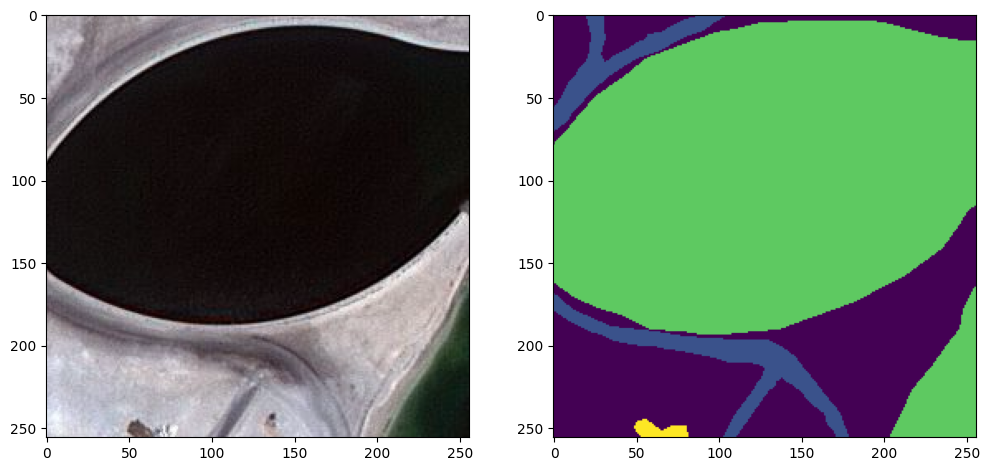

In [ ]:
#Another Sanity check, view few images
image_number = random.randint(0, len(image_dataset))
plt.figure(figsize=(12, 6))
plt.subplot(121)
plt.imshow(image_dataset[image_number])
plt.subplot(122)
plt.imshow(labels[image_number][:,:,0])
plt.show()

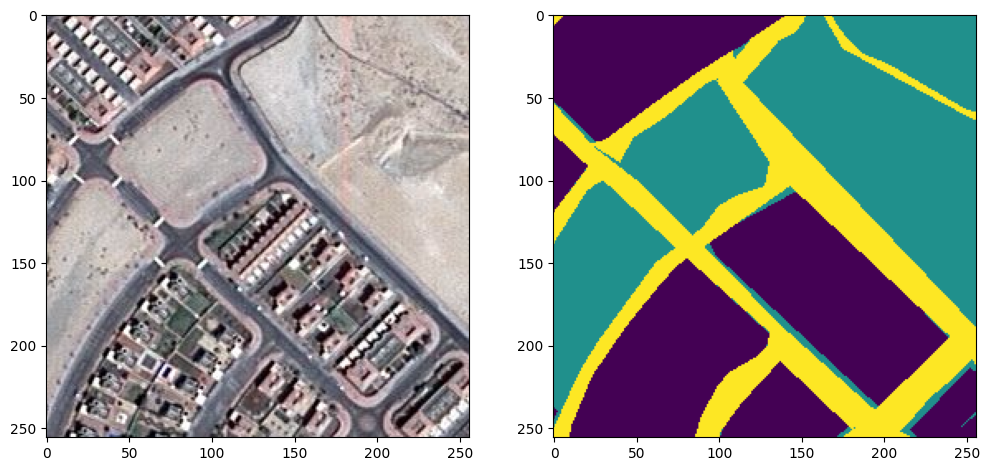

In [ ]:
#Another Sanity check, view few images
image_number = random.randint(0, len(image_dataset))
plt.figure(figsize=(12, 6))
plt.subplot(121)
plt.imshow(image_dataset[image_number])
plt.subplot(122)
plt.imshow(labels[image_number][:,:,0])
plt.show()

In [ ]:
import gc # Python's Garbage Collector

n_classes = len(np.unique(labels))
from keras.utils import to_categorical

# FIX 1: Add .astype(np.uint8) to force small memory usage
# This single change saves ~75% of the RAM required for this array!
labels_cat = to_categorical(labels, num_classes=n_classes).astype(np.uint8)

# FIX 2: Delete old, massive variables we no longer need before splitting
# We already have image_dataset and labels_cat, so we don't need these anymore.
del labels
del mask_dataset

# Force Python to actually empty the deleted data from RAM immediately
gc.collect()

from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(image_dataset, labels_cat, test_size = 0.20, random_state = 42)

print("Split successful! Ready for training.")

Split successful! Ready for training.


In [ ]:
from keras.models import Model
from keras.layers import Input, Conv2D, MaxPooling2D, UpSampling2D, concatenate, Conv2DTranspose, BatchNormalization, Dropout, Lambda
from keras import backend as K

def jacard_coef(y_true, y_pred):
    y_true_f = K.flatten(y_true)
    y_pred_f = K.flatten(y_pred)
    intersection = K.sum(y_true_f * y_pred_f) # Calculates overlapping target pixels.
    return (intersection + 1.0) / (K.sum(y_true_f) + K.sum(y_pred_f) - intersection + 1.0) #Computes IoU score (adds 1.0 to avoid division by zero)



################################################################
def multi_unet_model(n_classes=4, IMG_HEIGHT=256, IMG_WIDTH=256, IMG_CHANNELS=1): # n_classes is 4 by default so if someone forget to pass any arguments
#Build the model
    inputs = Input((IMG_HEIGHT, IMG_WIDTH, IMG_CHANNELS))
    #s = Lambda(lambda x: x / 255)(inputs)   #No need for this if we normalize our inputs beforehand like minmaxScalar
    s = inputs

    #Contraction path : Encoder of U-Net used to capture the objects , textures.. of the image ,
    # MaxPooling lagta hai, jisse image ki spatial height aur width aadhi hoti chali jati hai (256x256  -> 128x128 -> 64x64)
    #as the image getting smaller and smaller , the depth increases
    c1 = Conv2D(16, (3, 3), activation='relu', kernel_initializer='he_normal', padding='same')(s)
    c1 = Dropout(0.2)(c1)  # Original research paper uses 0.1
    #dropout 0.2 disables 20% neurons temporarily in every batch while training to avaoid overfitting
    c1 = Conv2D(16, (3, 3), activation='relu', kernel_initializer='he_normal', padding='same')(c1)
    p1 = MaxPooling2D((2, 2))(c1)

    #ReLU is Rectified Linear Unit -> max(0,x) , for negative it o/p as 0 and for positive it o/p as the the number as it is.
    # setting the starting weights of a neural network layer using a specific statistical method called He normal initialization (or Kaiming initialization).
    # padding='same' is a setting that keeps your output image size exactly equal to your input image size. It automatically adds a border of zeros (called zero-padding) around the original image

    c2 = Conv2D(32, (3, 3), activation='relu', kernel_initializer='he_normal', padding='same')(p1)
    c2 = Dropout(0.2)(c2)  # Original 0.1
    c2 = Conv2D(32, (3, 3), activation='relu', kernel_initializer='he_normal', padding='same')(c2)
    p2 = MaxPooling2D((2, 2))(c2)

    c3 = Conv2D(64, (3, 3), activation='relu', kernel_initializer='he_normal', padding='same')(p2)
    c3 = Dropout(0.2)(c3)
    c3 = Conv2D(64, (3, 3), activation='relu', kernel_initializer='he_normal', padding='same')(c3)
    p3 = MaxPooling2D((2, 2))(c3)

    c4 = Conv2D(128, (3, 3), activation='relu', kernel_initializer='he_normal', padding='same')(p3)
    c4 = Dropout(0.2)(c4)
    c4 = Conv2D(128, (3, 3), activation='relu', kernel_initializer='he_normal', padding='same')(c4)
    p4 = MaxPooling2D(pool_size=(2, 2))(c4)

    c5 = Conv2D(256, (3, 3), activation='relu', kernel_initializer='he_normal', padding='same')(p4)
    c5 = Dropout(0.3)(c5)
    c5 = Conv2D(256, (3, 3), activation='relu', kernel_initializer='he_normal', padding='same')(c5)

    #Expansive path
    u6 = Conv2DTranspose(128, (2, 2), strides=(2, 2), padding='same')(c5)
    u6 = concatenate([u6, c4])
    c6 = Conv2D(128, (3, 3), activation='relu', kernel_initializer='he_normal', padding='same')(u6)
    c6 = Dropout(0.2)(c6)
    c6 = Conv2D(128, (3, 3), activation='relu', kernel_initializer='he_normal', padding='same')(c6)

    u7 = Conv2DTranspose(64, (2, 2), strides=(2, 2), padding='same')(c6)
    u7 = concatenate([u7, c3])
    c7 = Conv2D(64, (3, 3), activation='relu', kernel_initializer='he_normal', padding='same')(u7)
    c7 = Dropout(0.2)(c7)
    c7 = Conv2D(64, (3, 3), activation='relu', kernel_initializer='he_normal', padding='same')(c7)

    u8 = Conv2DTranspose(32, (2, 2), strides=(2, 2), padding='same')(c7)
    u8 = concatenate([u8, c2])
    c8 = Conv2D(32, (3, 3), activation='relu', kernel_initializer='he_normal', padding='same')(u8)
    c8 = Dropout(0.2)(c8)  # Original 0.1
    c8 = Conv2D(32, (3, 3), activation='relu', kernel_initializer='he_normal', padding='same')(c8)

    u9 = Conv2DTranspose(16, (2, 2), strides=(2, 2), padding='same')(c8)
    u9 = concatenate([u9, c1], axis=3)
    c9 = Conv2D(16, (3, 3), activation='relu', kernel_initializer='he_normal', padding='same')(u9)
    c9 = Dropout(0.2)(c9)  # Original 0.1
    c9 = Conv2D(16, (3, 3), activation='relu', kernel_initializer='he_normal', padding='same')(c9)

    outputs = Conv2D(n_classes, (1, 1), activation='softmax')(c9)

    model = Model(inputs=[inputs], outputs=[outputs])

    #NOTE: Compile the model in the main program to make it easy to test with various loss functions
    #model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

    #model.summary()

    return model

In [ ]:
#######################################
#Parameters for model
weights = [0.1666, 0.1666, 0.1666, 0.1666, 0.1666, 0.1666]
dice_loss = sm.losses.DiceLoss(class_weights=weights)
focal_loss = sm.losses.CategoricalFocalLoss()
total_loss = dice_loss + (1 * focal_loss)

# The shape of X_train looks something like (1044, 256, 256, 3)
IMG_HEIGHT = X_train.shape[1]
IMG_WIDTH  = X_train.shape[2]
IMG_CHANNELS = X_train.shape[3]

# ----------------- FIX STARTS HERE -----------------
import tensorflow as tf

# Redefine the Jaccard Coefficient metric using modern TensorFlow syntax
def jacard_coef(y_true, y_pred):
    # Ensure both arrays are float32 to prevent math type-mismatch errors
    y_true = tf.cast(y_true, tf.float32)
    y_pred = tf.cast(y_pred, tf.float32)

    # Use tf.reshape([-1]) instead of the deprecated K.flatten()
    y_true_f = tf.reshape(y_true, [-1])
    y_pred_f = tf.reshape(y_pred, [-1])

    # Calculate intersection and union
    intersection = tf.reduce_sum(y_true_f * y_pred_f)
    union = tf.reduce_sum(y_true_f) + tf.reduce_sum(y_pred_f) - intersection

    # Add a tiny smoothing value (1e-15) to prevent dividing by zero
    return (intersection + 1e-15) / (union + 1e-15)
# ----------------- FIX ENDS HERE -----------------

# Now use our patched function in the metrics list
metrics=['accuracy', jacard_coef]

def get_model():
    return multi_unet_model(n_classes=n_classes, IMG_HEIGHT=IMG_HEIGHT, IMG_WIDTH=IMG_WIDTH, IMG_CHANNELS=IMG_CHANNELS)

model = get_model()
model.compile(optimizer='adam', loss=total_loss, metrics=metrics)

model.summary()

history1 = model.fit(X_train, y_train,
                    batch_size = 16,
                    verbose=1,
                    epochs=100,
                    validation_data=(X_test, y_test),
                    shuffle= True)
#Minmaxscaler
#With weights...[0.1666, 0.1666, 0.1666, 0.1666, 0.1666, 0.1666]   in Dice loss
#With focal loss only, after 100 epochs val jacard is: 0.62  (Mean IoU: 0.6)
#With dice loss only, after 100 epochs val jacard is: 0.74 (Reached 0.7 in 40 epochs)
#With dice + 5 focal, after 100 epochs val jacard is: 0.711 (Mean IoU: 0.611)
##With dice + 1 focal, after 100 epochs val jacard is: 0.75 (Mean IoU: 0.62)
#Using categorical crossentropy as loss: 0.71

##With calculated weights in Dice loss.(The automatic calculator for balanced classes (Commented above, we will be using that if the classes were more balanced like 20% of each class and 5 classes ))
#With dice loss only, after 100 epochs val jacard is: 0.672 (0.52 iou)


##Standardscaler
#Using categorical crossentropy as loss: 0.677

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 256, 256,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_19 (Conv2D)  │ (None, 256, 256,  │        448 │ input_layer_1[0]… │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_9 (Dropout) │ (None, 256, 256,  │          0 │ conv2d_19[0][0]   │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_20 (Conv2D)  │ (None, 256, 256,  │      2,320 │ dropout_9[0][0]   │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_4     │ (None, 128, 128,  │          0 │ conv2d_20[0][0]   │
│ (MaxPooling2D)      │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_21 (Conv2D)  │ (None, 128, 128,  │      4,640 │ max_pooling2d_4[… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_10          │ (None, 128, 128,  │          0 │ conv2d_21[0][0]   │
│ (Dropout)           │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_22 (Conv2D)  │ (None, 128, 128,  │      9,248 │ dropout_10[0][0]  │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_5     │ (None, 64, 64,    │          0 │ conv2d_22[0][0]   │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_23 (Conv2D)  │ (None, 64, 64,    │     18,496 │ max_pooling2d_5[… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_11          │ (None, 64, 64,    │          0 │ conv2d_23[0][0]   │
│ (Dropout)           │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_24 (Conv2D)  │ (None, 64, 64,    │     36,928 │ dropout_11[0][0]  │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_6     │ (None, 32, 32,    │          0 │ conv2d_24[0][0]   │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_25 (Conv2D)  │ (None, 32, 32,    │     73,856 │ max_pooling2d_6[… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_12          │ (None, 32, 32,    │          0 │ conv2d_25[0][0]   │
│ (Dropout)           │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_26 (Conv2D)  │ (None, 32, 32,    │    147,584 │ dropout_12[0][0]  │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_7     │ (None, 16, 16,    │          0 │ conv2d_26[0][0] 

 Total params: 1,941,190 (7.41 MB)

 Trainable params: 1,941,190 (7.41 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/100
66/66 ━━━━━━━━━━━━━━━━━━━━ 77s 629ms/step - accuracy: 0.5438 - jacard_coef: 0.2791 - loss: 0.9952 - val_accuracy: 0.6855 - val_jacard_coef: 0.4163 - val_loss: 0.9655
Epoch 2/100
66/66 ━━━━━━━━━━━━━━━━━━━━ 11s 171ms/step - accuracy: 0.6737 - jacard_coef: 0.4217 - loss: 0.9646 - val_accuracy: 0.6685 - val_jacard_coef: 0.4346 - val_loss: 0.9724
Epoch 3/100
66/66 ━━━━━━━━━━━━━━━━━━━━ 12s 176ms/step - accuracy: 0.7207 - jacard_coef: 0.4643 - loss: 0.9564 - val_accuracy: 0.6991 - val_jacard_coef: 0.4713 - val_loss: 0.9663
Epoch 4/100
66/66 ━━━━━━━━━━━━━━━━━━━━ 20s 169ms/step - accuracy: 0.7416 - jacard_coef: 0.4883 - loss: 0.9508 - val_accuracy: 0.7319 - val_jacard_coef: 0.4976 - val_loss: 0.9562
Epoch 5/100
66/66 ━━━━━━━━━━━━━━━━━━━━ 11s 172ms/step - accuracy: 0.7578 - jacard_coef: 0.5130 - loss: 0.9450 - val_accuracy: 0.7026 - val_jacard_coef: 0.4637 - val_loss: 0.9683
Epoch 6/100
66/66 ━━━━━━━━━━━━━━━━━━━━ 11s 170ms/step - accuracy: 0.7732 - jacard_coef: 0.5384 - loss: 0.9405 

In [ ]:
from google.colab import drive
import os

# 1. Mount your Google Drive (This will pop up a window asking for permission)
drive.mount('/content/drive')

# 2. Define the exact folder path inside your Google Drive
# 'MyDrive' represents the main homepage of your Google Drive
drive_save_folder = '/content/drive/MyDrive/UNet_Satellite_Models'

# 3. Check if this folder exists in your Drive, and create it if it doesn't
if not os.path.exists(drive_save_folder):
    os.makedirs(drive_save_folder)
    print(f"Created directory in Google Drive: {drive_save_folder}")
else:
    print(f"Directory {drive_save_folder} already exists in Google Drive.")

# 4. Combine the folder path with your desired file name
model_path = os.path.join(drive_save_folder, 'satellite_standard_unet_100epochs.hdf5')

# 5. Save the compiled and trained model directly to that path
model.save(model_path)
print(f"Model successfully saved to your Google Drive at: {model_path}")


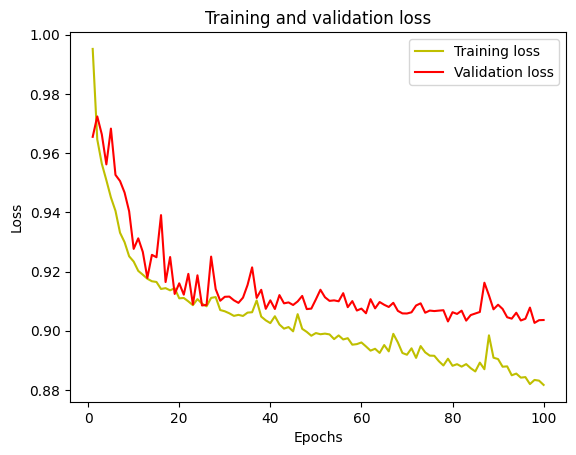

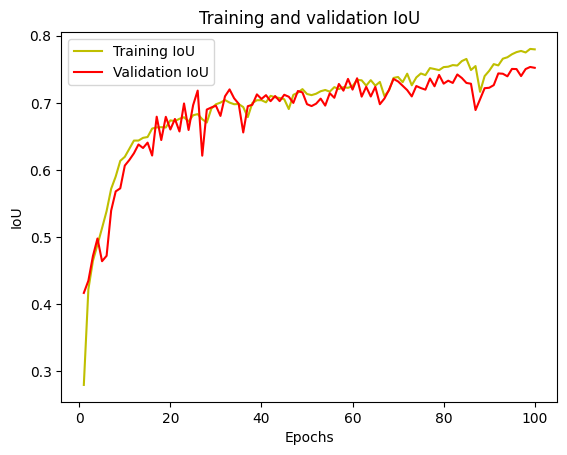

9/9 ━━━━━━━━━━━━━━━━━━━━ 13s 239ms/step
Mean IoU = 0.62164885
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step


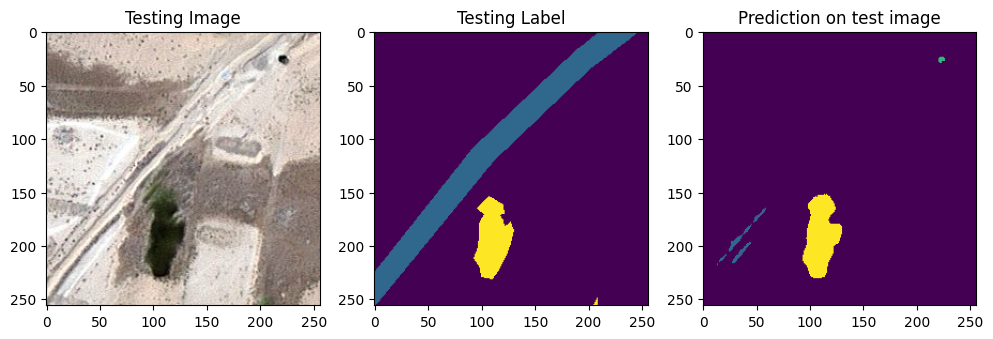

In [ ]:
###########################################################

# Assign the training history object to a simpler variable name.
history = history1

# Extract the list of training error scores from the history dictionary.
loss = history.history['loss']

# Extract the list of validation (test) error scores from the history dictionary.
val_loss = history.history['val_loss']

# Create a list of numbers from 1 to the total number of epochs for the x-axis.
epochs = range(1, len(loss) + 1)

# Plot the training loss on the graph as a yellow ('y') line.
plt.plot(epochs, loss, 'y', label='Training loss')

# Plot the validation loss on the graph as a red ('r') line.
plt.plot(epochs, val_loss, 'r', label='Validation loss')

# Add a title to the top of the loss graph.
plt.title('Training and validation loss')

# Label the x-axis as 'Epochs'.
plt.xlabel('Epochs')

# Label the y-axis as 'Loss'.
plt.ylabel('Loss')

# Display the legend to show what the yellow and red lines represent.
plt.legend()

# Render and display the complete loss graph on your screen.
plt.show()


# Extract the list of training IoU (accuracy) scores from the history dictionary.
acc = history.history['jacard_coef']

# Extract the list of validation IoU scores from the history dictionary.
val_acc = history.history['val_jacard_coef']

# Plot the training IoU on the graph as a yellow line.
plt.plot(epochs, acc, 'y', label='Training IoU')

# Plot the validation IoU on the graph as a red line.
plt.plot(epochs, val_acc, 'r', label='Validation IoU')

# Add a title to the top of the IoU graph.
plt.title('Training and validation IoU')

# Label the x-axis as 'Epochs'.
plt.xlabel('Epochs')

# Label the y-axis as 'IoU'.
plt.ylabel('IoU')

# Display the legend for the IoU graph.
plt.legend()

# Render and display the complete IoU graph on your screen.
plt.show()


##################################
# Note: Ensure the model is saved before loading it from a file path

# Import the Keras function needed to load a previously saved model file.
# from keras.models import load_model

# Load the specific saved .hdf5 model file from your directory.
# model = load_model("models/satellite_standard_unet_100epochs.hdf5",

# Tell Keras how to understand the custom loss function we built during training.
#                    custom_objects={'dice_loss_plus_2focal_loss': total_loss,

# Tell Keras how to understand the custom Jaccard metric we used.
#                                    'jacard_coef':jacard_coef})


# Give the model the test images and get its raw percentage predictions for every pixel.
y_pred=model.predict(X_test)

# Convert those raw percentages into final integer class labels (0 to 5) by picking the highest probability.
y_pred_argmax=np.argmax(y_pred, axis=3)

# Convert the true answer key (which was one-hot encoded) back into single integer labels so they match the predictions.
y_test_argmax=np.argmax(y_test, axis=3)


# Import the standard Keras function for calculating Mean Intersection over Union.
from keras.metrics import MeanIoU

# Define the total number of classes (categories) in our dataset.
n_classes = 6

# Initialize the MeanIoU calculator and tell it we have 6 categories.
IOU_keras = MeanIoU(num_classes=n_classes)

# Feed the true answers and the model's predictions into the calculator.
IOU_keras.update_state(y_test_argmax, y_pred_argmax)

# Calculate the final average IoU score and print it to the screen.
print("Mean IoU =", IOU_keras.result().numpy())


#######################################################################
#Predict on a few images

# Import Python's built-in random number generator library.
import random

# Pick a random number between 0 and the total amount of test images we have.
test_img_number = random.randint(0, len(X_test))

# Grab the actual test image that corresponds to that random number.
test_img = X_test[test_img_number]

# Grab the true mask (the perfect answer key) for that exact same image.
ground_truth=y_test_argmax[test_img_number]

# (Commented out) An alternative way to normalize a single-channel image.
#test_img_norm=test_img[:,:,0][:,:,None]

# Add a fake "batch" dimension to the single image because the model only accepts lists of images.
test_img_input=np.expand_dims(test_img, 0)

# Feed this properly formatted single image into the model to get a prediction.
prediction = (model.predict(test_img_input))

# Convert the single prediction into integer labels and remove that fake batch dimension we just added.
predicted_img=np.argmax(prediction, axis=3)[0,:,:]


# Create a blank canvas to draw our images on, making it 12 inches wide and 8 inches tall.
plt.figure(figsize=(12, 8))

# Create a grid of 2 rows and 3 columns, and select the 1st position for the next image.
plt.subplot(231)

# Add a title above the first image.
plt.title('Testing Image')

# Draw the original satellite test image on the canvas.
plt.imshow(test_img)

# Select the 2nd position in the grid for the next image.
plt.subplot(232)

# Add a title above the second image.
plt.title('Testing Label')

# Draw the true, perfect ground-truth mask on the canvas.
plt.imshow(ground_truth)

# Select the 3rd position in the grid for the final image.
plt.subplot(233)

# Add a title above the third image.
plt.title('Prediction on test image')

# Draw the model's generated prediction mask on the canvas.
plt.imshow(predicted_img)

# Render and display the side-by-side visual comparison on your screen.
plt.show()

#####################################################################

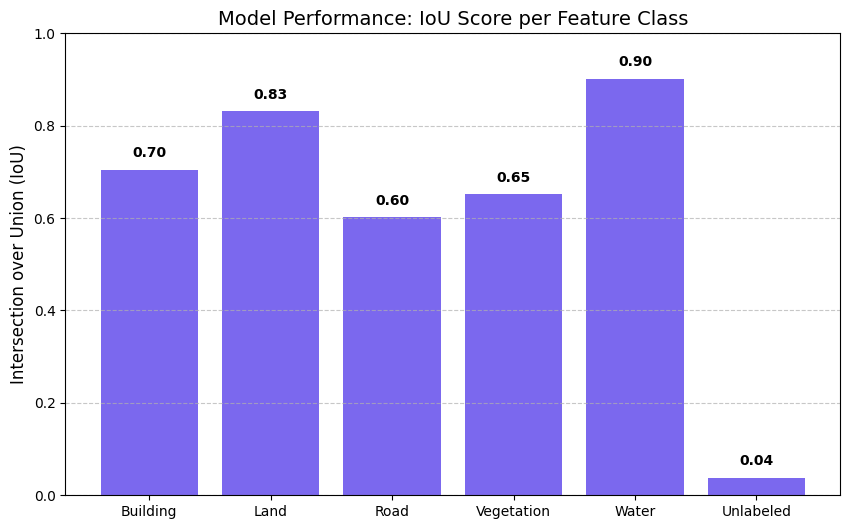

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix
import gc

# 1. Free up any dangling memory first to keep the Colab session safe
gc.collect()

# 2. Define your exact class names based on the MBRSC Dubai dataset
class_names = ['Building', 'Land', 'Road', 'Vegetation', 'Water', 'Unlabeled']

# 3. Flatten the test and prediction arrays to 1D lists for the calculator
# This is safe for RAM because we are only flattening the 20% test set, not the whole dataset
y_test_flat = y_test_argmax.flatten()
y_pred_flat = y_pred_argmax.flatten()

# 4. Generate a Confusion Matrix
# This counts exactly how many pixels of Class A were predicted as Class B
cm = confusion_matrix(y_test_flat, y_pred_flat)

# 5. Calculate IoU for each individual class
# Formula: Intersection / (True_Pixels + Predicted_Pixels - Intersection)
intersection = np.diag(cm)
ground_truth_set = cm.sum(axis=1)
predicted_set = cm.sum(axis=0)
union = ground_truth_set + predicted_set - intersection

# Add a tiny number (1e-15) to the denominator to prevent a "divide by zero" crash
iou_per_class = intersection / (union.astype(float) + 1e-15)

# 6. Plot the results as a clean, professional Bar Chart
plt.figure(figsize=(10, 6))
bars = plt.bar(class_names, iou_per_class, color='mediumslateblue')
plt.title('Model Performance: IoU Score per Feature Class', fontsize=14)
plt.ylabel('Intersection over Union (IoU)', fontsize=12)
plt.ylim(0, 1.0) # Keep the scale from 0 to 1 (0% to 100%)

# 7. Add the exact numerical score on top of each bar for easy reading
for bar, iou_score in zip(bars, iou_per_class):
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 0.02, f"{iou_score:.2f}", ha='center', va='bottom', fontweight='bold')

plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

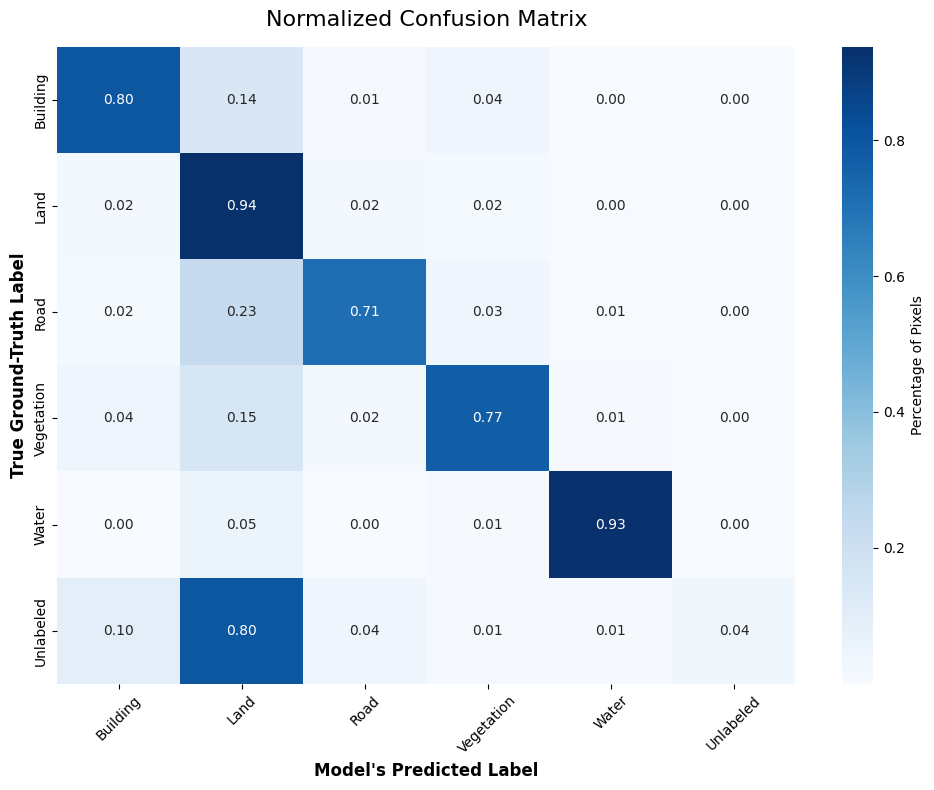

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import gc

# 1. Clear any loose memory just to be safe
gc.collect()

# 2. Normalize the confusion matrix
# This converts the raw pixel counts into percentages (0.0 to 1.0) so we can see
# the proportion of correct vs. incorrect guesses for each class.
# We add a tiny number (1e-15) to prevent division-by-zero errors.
cm_normalized = cm.astype('float') / (cm.sum(axis=1)[:, np.newaxis] + 1e-15)

# 3. Set up the visual canvas
plt.figure(figsize=(10, 8))

# 4. Create the heatmap using Seaborn
# annot=True puts the numbers in the boxes, fmt=".2f" rounds to 2 decimal places
sns.heatmap(cm_normalized, annot=True, fmt=".2f", cmap="Blues",
            xticklabels=class_names, yticklabels=class_names,
            cbar_kws={'label': 'Percentage of Pixels'})

# 5. Add professional labels for the research paper
plt.title('Normalized Confusion Matrix', fontsize=16, pad=15)
plt.ylabel('True Ground-Truth Label', fontsize=12, fontweight='bold')
plt.xlabel('Model\'s Predicted Label', fontsize=12, fontweight='bold')

# Rotate the x-axis labels so they don't overlap
plt.xticks(rotation=45)

# Ensure everything fits cleanly in the image frame
plt.tight_layout()
plt.show()

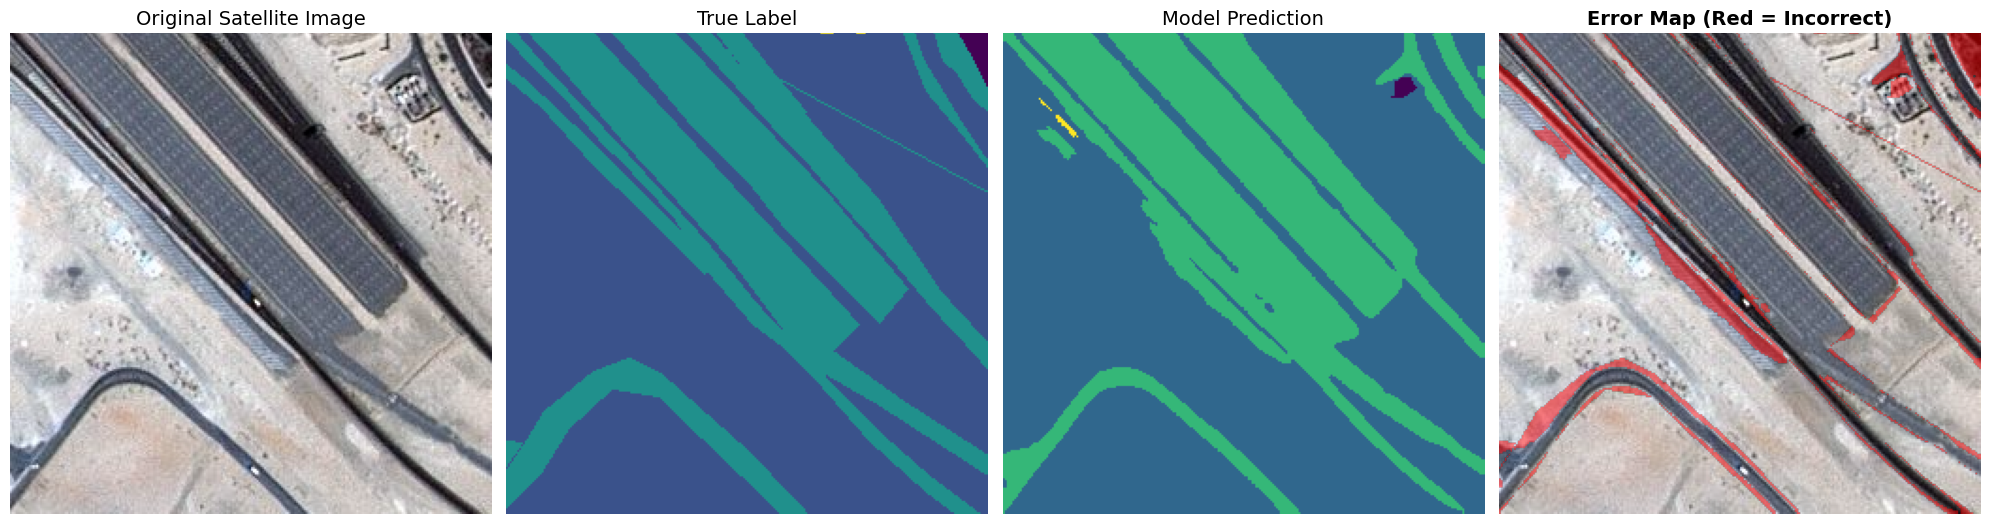

In [ ]:
import random
import numpy as np
import matplotlib.pyplot as plt
import gc

# 1. Clear memory to keep the Colab session safe
gc.collect()

# 2. Pick a random test image from your test set
test_img_number = random.randint(0, len(X_test) - 1)
test_img = X_test[test_img_number]
ground_truth = y_test_argmax[test_img_number]

# 3. Get the model's prediction for this specific image
test_img_input = np.expand_dims(test_img, 0)
prediction = model.predict(test_img_input, verbose=0)
predicted_img = np.argmax(prediction, axis=3)[0,:,:]

# 4. Generate the Error Mask
# This creates a binary array: True (1) where the model was wrong, False (0) where it was right
error_mask = (ground_truth != predicted_img)

# 5. Set up the visual canvas
plt.figure(figsize=(20, 6))

# Plot 1: The Original Satellite Image
plt.subplot(141)
plt.title('Original Satellite Image', fontsize=14)
plt.imshow(test_img)
plt.axis('off')

# Plot 2: The Perfect Ground Truth Label
plt.subplot(142)
plt.title('True Label', fontsize=14)
plt.imshow(ground_truth, cmap='viridis')
plt.axis('off')

# Plot 3: The Model's Prediction
plt.subplot(143)
plt.title('Model Prediction', fontsize=14)
plt.imshow(predicted_img, cmap='viridis')
plt.axis('off')

# Plot 4: The Error Highlight Map
plt.subplot(144)
plt.title('Error Map (Red = Incorrect)', fontsize=14, fontweight='bold')
# Draw the original image first
plt.imshow(test_img)
# Overlay the errors in pure red with 50% transparency so you can see what is underneath
error_overlay = np.zeros_like(test_img)
error_overlay[:, :, 0] = 255 # Red channel maxed out
plt.imshow(np.ma.masked_where(error_mask == False, error_mask), cmap='autumn', alpha=0.5)
plt.axis('off')

plt.tight_layout()
plt.show()

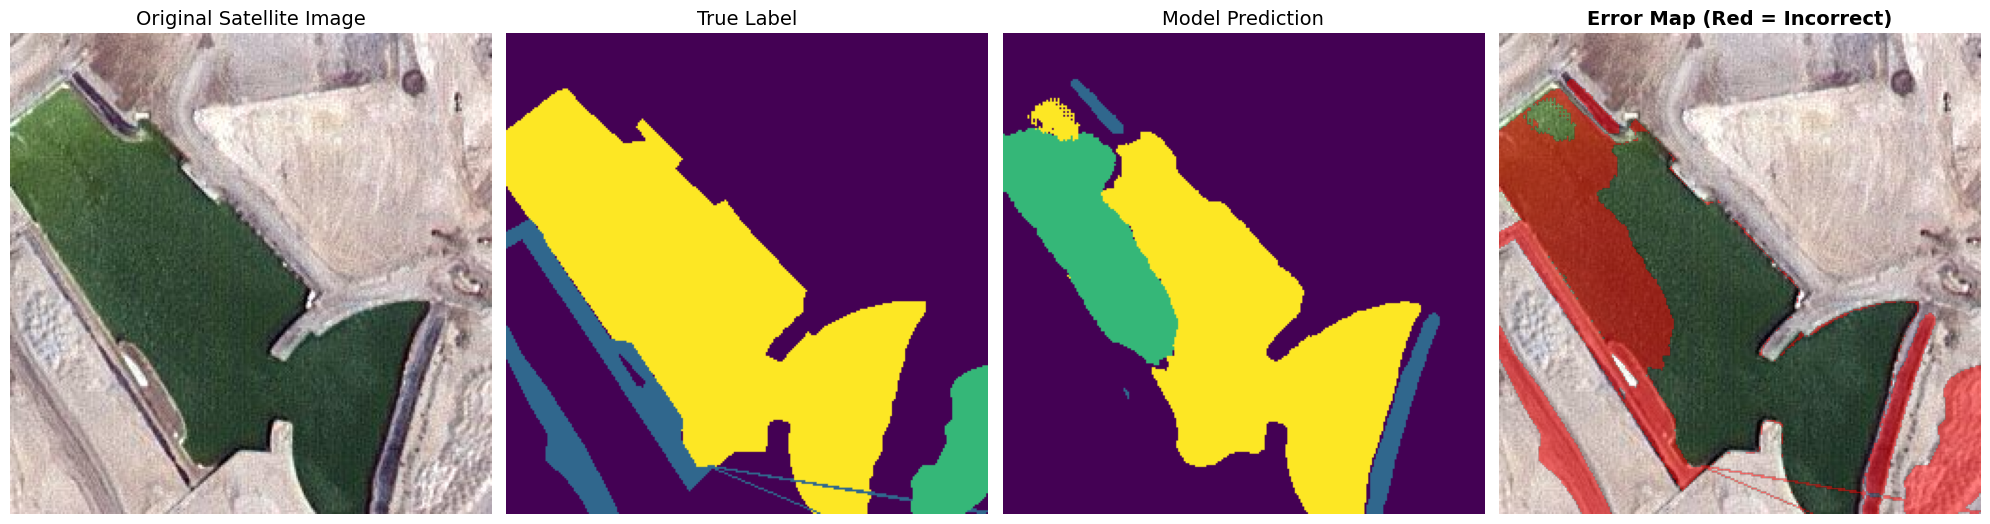

In [ ]:
import random
import numpy as np
import matplotlib.pyplot as plt
import gc

# 1. Clear memory to keep the Colab session safe
gc.collect()

# 2. Pick a random test image from your test set
test_img_number = random.randint(0, len(X_test) - 1)
test_img = X_test[test_img_number]
ground_truth = y_test_argmax[test_img_number]

# 3. Get the model's prediction for this specific image
test_img_input = np.expand_dims(test_img, 0)
prediction = model.predict(test_img_input, verbose=0)
predicted_img = np.argmax(prediction, axis=3)[0,:,:]

# 4. Generate the Error Mask
# This creates a binary array: True (1) where the model was wrong, False (0) where it was right
error_mask = (ground_truth != predicted_img)

# 5. Set up the visual canvas
plt.figure(figsize=(20, 6))

# Plot 1: The Original Satellite Image
plt.subplot(141)
plt.title('Original Satellite Image', fontsize=14)
plt.imshow(test_img)
plt.axis('off')

# Plot 2: The Perfect Ground Truth Label
plt.subplot(142)
plt.title('True Label', fontsize=14)
plt.imshow(ground_truth, cmap='viridis')
plt.axis('off')

# Plot 3: The Model's Prediction
plt.subplot(143)
plt.title('Model Prediction', fontsize=14)
plt.imshow(predicted_img, cmap='viridis')
plt.axis('off')

# Plot 4: The Error Highlight Map
plt.subplot(144)
plt.title('Error Map (Red = Incorrect)', fontsize=14, fontweight='bold')
# Draw the original image first
plt.imshow(test_img)
# Overlay the errors in pure red with 50% transparency so you can see what is underneath
error_overlay = np.zeros_like(test_img)
error_overlay[:, :, 0] = 255 # Red channel maxed out
plt.imshow(np.ma.masked_where(error_mask == False, error_mask), cmap='autumn', alpha=0.5)
plt.axis('off')

plt.tight_layout()
plt.show()

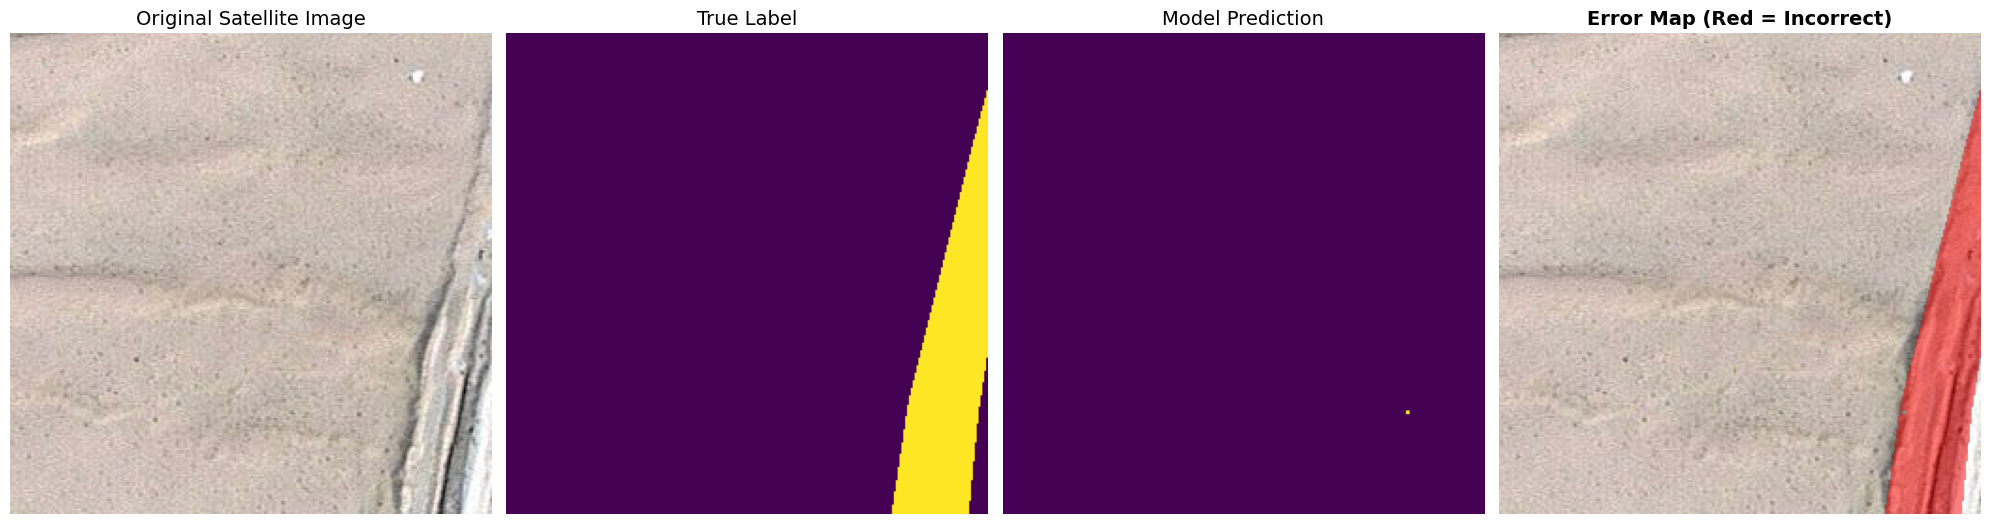

In [ ]:
import random
import numpy as np
import matplotlib.pyplot as plt
import gc

# 1. Clear memory to keep the Colab session safe
gc.collect()

# 2. Pick a random test image from your test set
test_img_number = random.randint(0, len(X_test) - 1)
test_img = X_test[test_img_number]
ground_truth = y_test_argmax[test_img_number]

# 3. Get the model's prediction for this specific image
test_img_input = np.expand_dims(test_img, 0)
prediction = model.predict(test_img_input, verbose=0)
predicted_img = np.argmax(prediction, axis=3)[0,:,:]

# 4. Generate the Error Mask
# This creates a binary array: True (1) where the model was wrong, False (0) where it was right
error_mask = (ground_truth != predicted_img)

# 5. Set up the visual canvas
plt.figure(figsize=(20, 6))

# Plot 1: The Original Satellite Image
plt.subplot(141)
plt.title('Original Satellite Image', fontsize=14)
plt.imshow(test_img)
plt.axis('off')

# Plot 2: The Perfect Ground Truth Label
plt.subplot(142)
plt.title('True Label', fontsize=14)
plt.imshow(ground_truth, cmap='viridis')
plt.axis('off')

# Plot 3: The Model's Prediction
plt.subplot(143)
plt.title('Model Prediction', fontsize=14)
plt.imshow(predicted_img, cmap='viridis')
plt.axis('off')

# Plot 4: The Error Highlight Map
plt.subplot(144)
plt.title('Error Map (Red = Incorrect)', fontsize=14, fontweight='bold')
# Draw the original image first
plt.imshow(test_img)
# Overlay the errors in pure red with 50% transparency so you can see what is underneath
error_overlay = np.zeros_like(test_img)
error_overlay[:, :, 0] = 255 # Red channel maxed out
plt.imshow(np.ma.masked_where(error_mask == False, error_mask), cmap='autumn', alpha=0.5)
plt.axis('off')

plt.tight_layout()
plt.show()

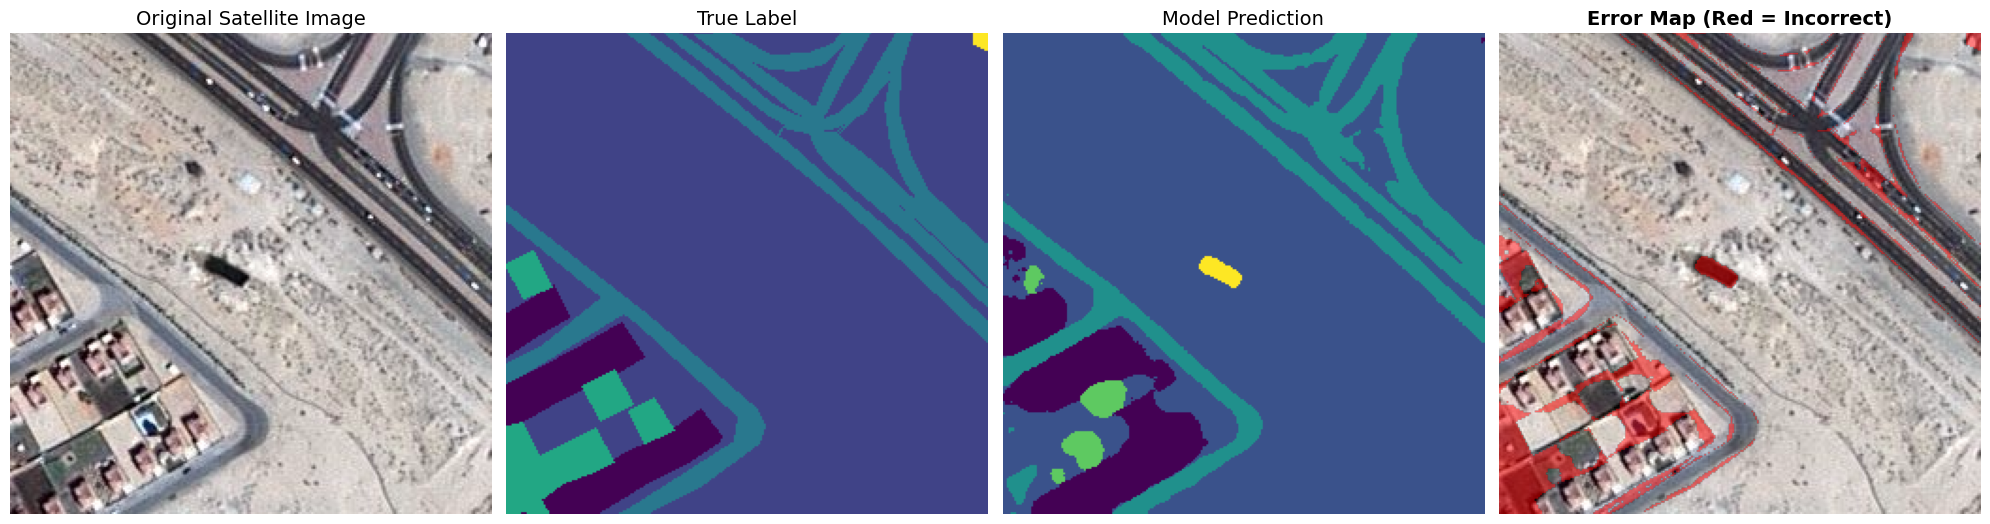

In [ ]:
import random
import numpy as np
import matplotlib.pyplot as plt
import gc

# 1. Clear memory to keep the Colab session safe
gc.collect()

# 2. Pick a random test image from your test set
test_img_number = random.randint(0, len(X_test) - 1)
test_img = X_test[test_img_number]
ground_truth = y_test_argmax[test_img_number]

# 3. Get the model's prediction for this specific image
test_img_input = np.expand_dims(test_img, 0)
prediction = model.predict(test_img_input, verbose=0)
predicted_img = np.argmax(prediction, axis=3)[0,:,:]

# 4. Generate the Error Mask
# This creates a binary array: True (1) where the model was wrong, False (0) where it was right
error_mask = (ground_truth != predicted_img)

# 5. Set up the visual canvas
plt.figure(figsize=(20, 6))

# Plot 1: The Original Satellite Image
plt.subplot(141)
plt.title('Original Satellite Image', fontsize=14)
plt.imshow(test_img)
plt.axis('off')

# Plot 2: The Perfect Ground Truth Label
plt.subplot(142)
plt.title('True Label', fontsize=14)
plt.imshow(ground_truth, cmap='viridis')
plt.axis('off')

# Plot 3: The Model's Prediction
plt.subplot(143)
plt.title('Model Prediction', fontsize=14)
plt.imshow(predicted_img, cmap='viridis')
plt.axis('off')

# Plot 4: The Error Highlight Map
plt.subplot(144)
plt.title('Error Map (Red = Incorrect)', fontsize=14, fontweight='bold')
# Draw the original image first
plt.imshow(test_img)
# Overlay the errors in pure red with 50% transparency so you can see what is underneath
error_overlay = np.zeros_like(test_img)
error_overlay[:, :, 0] = 255 # Red channel maxed out
plt.imshow(np.ma.masked_where(error_mask == False, error_mask), cmap='autumn', alpha=0.5)
plt.axis('off')

plt.tight_layout()
plt.show()

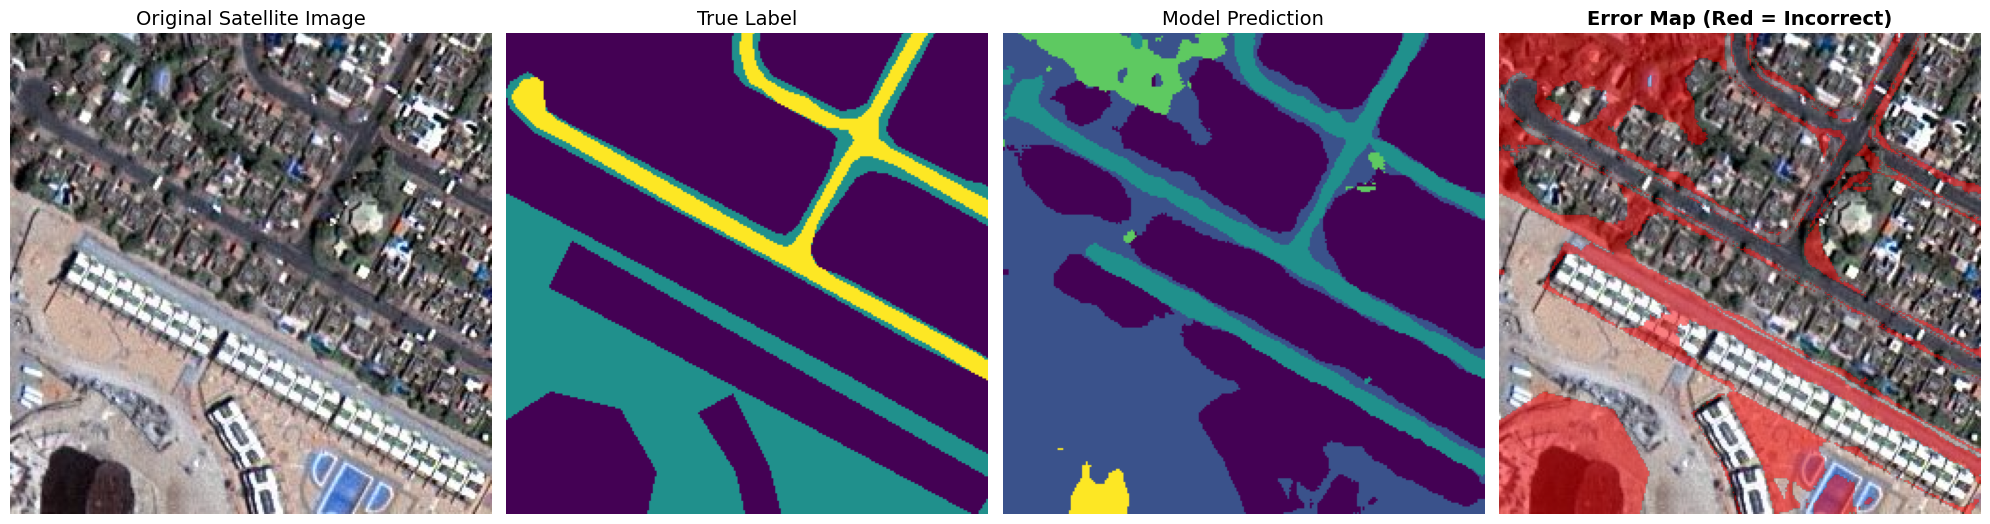

In [ ]:
import random
import numpy as np
import matplotlib.pyplot as plt
import gc

# 1. Clear memory to keep the Colab session safe
gc.collect()

# 2. Pick a random test image from your test set
test_img_number = random.randint(0, len(X_test) - 1)
test_img = X_test[test_img_number]
ground_truth = y_test_argmax[test_img_number]

# 3. Get the model's prediction for this specific image
test_img_input = np.expand_dims(test_img, 0)
prediction = model.predict(test_img_input, verbose=0)
predicted_img = np.argmax(prediction, axis=3)[0,:,:]

# 4. Generate the Error Mask
# This creates a binary array: True (1) where the model was wrong, False (0) where it was right
error_mask = (ground_truth != predicted_img)

# 5. Set up the visual canvas
plt.figure(figsize=(20, 6))

# Plot 1: The Original Satellite Image
plt.subplot(141)
plt.title('Original Satellite Image', fontsize=14)
plt.imshow(test_img)
plt.axis('off')

# Plot 2: The Perfect Ground Truth Label
plt.subplot(142)
plt.title('True Label', fontsize=14)
plt.imshow(ground_truth, cmap='viridis')
plt.axis('off')

# Plot 3: The Model's Prediction
plt.subplot(143)
plt.title('Model Prediction', fontsize=14)
plt.imshow(predicted_img, cmap='viridis')
plt.axis('off')

# Plot 4: The Error Highlight Map
plt.subplot(144)
plt.title('Error Map (Red = Incorrect)', fontsize=14, fontweight='bold')
# Draw the original image first
plt.imshow(test_img)
# Overlay the errors in pure red with 50% transparency so you can see what is underneath
error_overlay = np.zeros_like(test_img)
error_overlay[:, :, 0] = 255 # Red channel maxed out
plt.imshow(np.ma.masked_where(error_mask == False, error_mask), cmap='autumn', alpha=0.5)
plt.axis('off')

plt.tight_layout()
plt.show()

In [ ]:
import os

# 1. Create a dedicated folder in your Drive to hold your portfolio assets
save_dir = '/content/drive/MyDrive/UNet_Satellite_Portfolio/'
if not os.path.exists(save_dir):
    os.makedirs(save_dir)
    print(f"Created new directory: {save_dir}")

# 2. Re-plot and save the Loss Graph
plt.figure(figsize=(8, 6))
plt.plot(epochs, loss, 'y', label='Training loss')
plt.plot(epochs, val_loss, 'r', label='Validation loss')
plt.title('Training and validation loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.savefig(save_dir + '1_Loss_Graph.png', dpi=300, bbox_inches='tight')
plt.close() # Closes the figure to free up RAM!

# 3. Re-plot and save the IoU Graph
plt.figure(figsize=(8, 6))
plt.plot(epochs, acc, 'y', label='Training IoU')
plt.plot(epochs, val_acc, 'r', label='Validation IoU')
plt.title('Training and validation IoU')
plt.xlabel('Epochs')
plt.ylabel('IoU')
plt.legend()
plt.savefig(save_dir + '2_IoU_Graph.png', dpi=300, bbox_inches='tight')
plt.close()

# 4. Save the Normalized Confusion Matrix Heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(cm_normalized, annot=True, fmt=".2f", cmap="Blues",
            xticklabels=class_names, yticklabels=class_names,
            cbar_kws={'label': 'Percentage of Pixels'})
plt.title('Normalized Confusion Matrix', fontsize=16, pad=15)
plt.ylabel('True Ground-Truth Label', fontsize=12, fontweight='bold')
plt.xlabel('Model\'s Predicted Label', fontsize=12, fontweight='bold')
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(save_dir + '3_Confusion_Matrix.png', dpi=300, bbox_inches='tight')
plt.close()

# 5. Save the Class-Wise Bar Chart
plt.figure(figsize=(10, 6))
bars = plt.bar(class_names, iou_per_class, color='mediumslateblue')
plt.title('Model Performance: IoU Score per Feature Class', fontsize=14)
plt.ylabel('Intersection over Union (IoU)', fontsize=12)
plt.ylim(0, 1.0)
for bar, iou_score in zip(bars, iou_per_class):
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 0.02, f"{iou_score:.2f}", ha='center', va='bottom', fontweight='bold')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.savefig(save_dir + '4_Class_IoU_BarChart.png', dpi=300, bbox_inches='tight')
plt.close()

print(f"✅ Success! All high-resolution figures have been saved to: {save_dir}")

Scanning model architecture for Convolutional Layers...
Target locked on: conv2d_19. Extracting intermediate tensors...
Feature Map Shape extracted: (1, 256, 256, 16)
Rendering visuals...


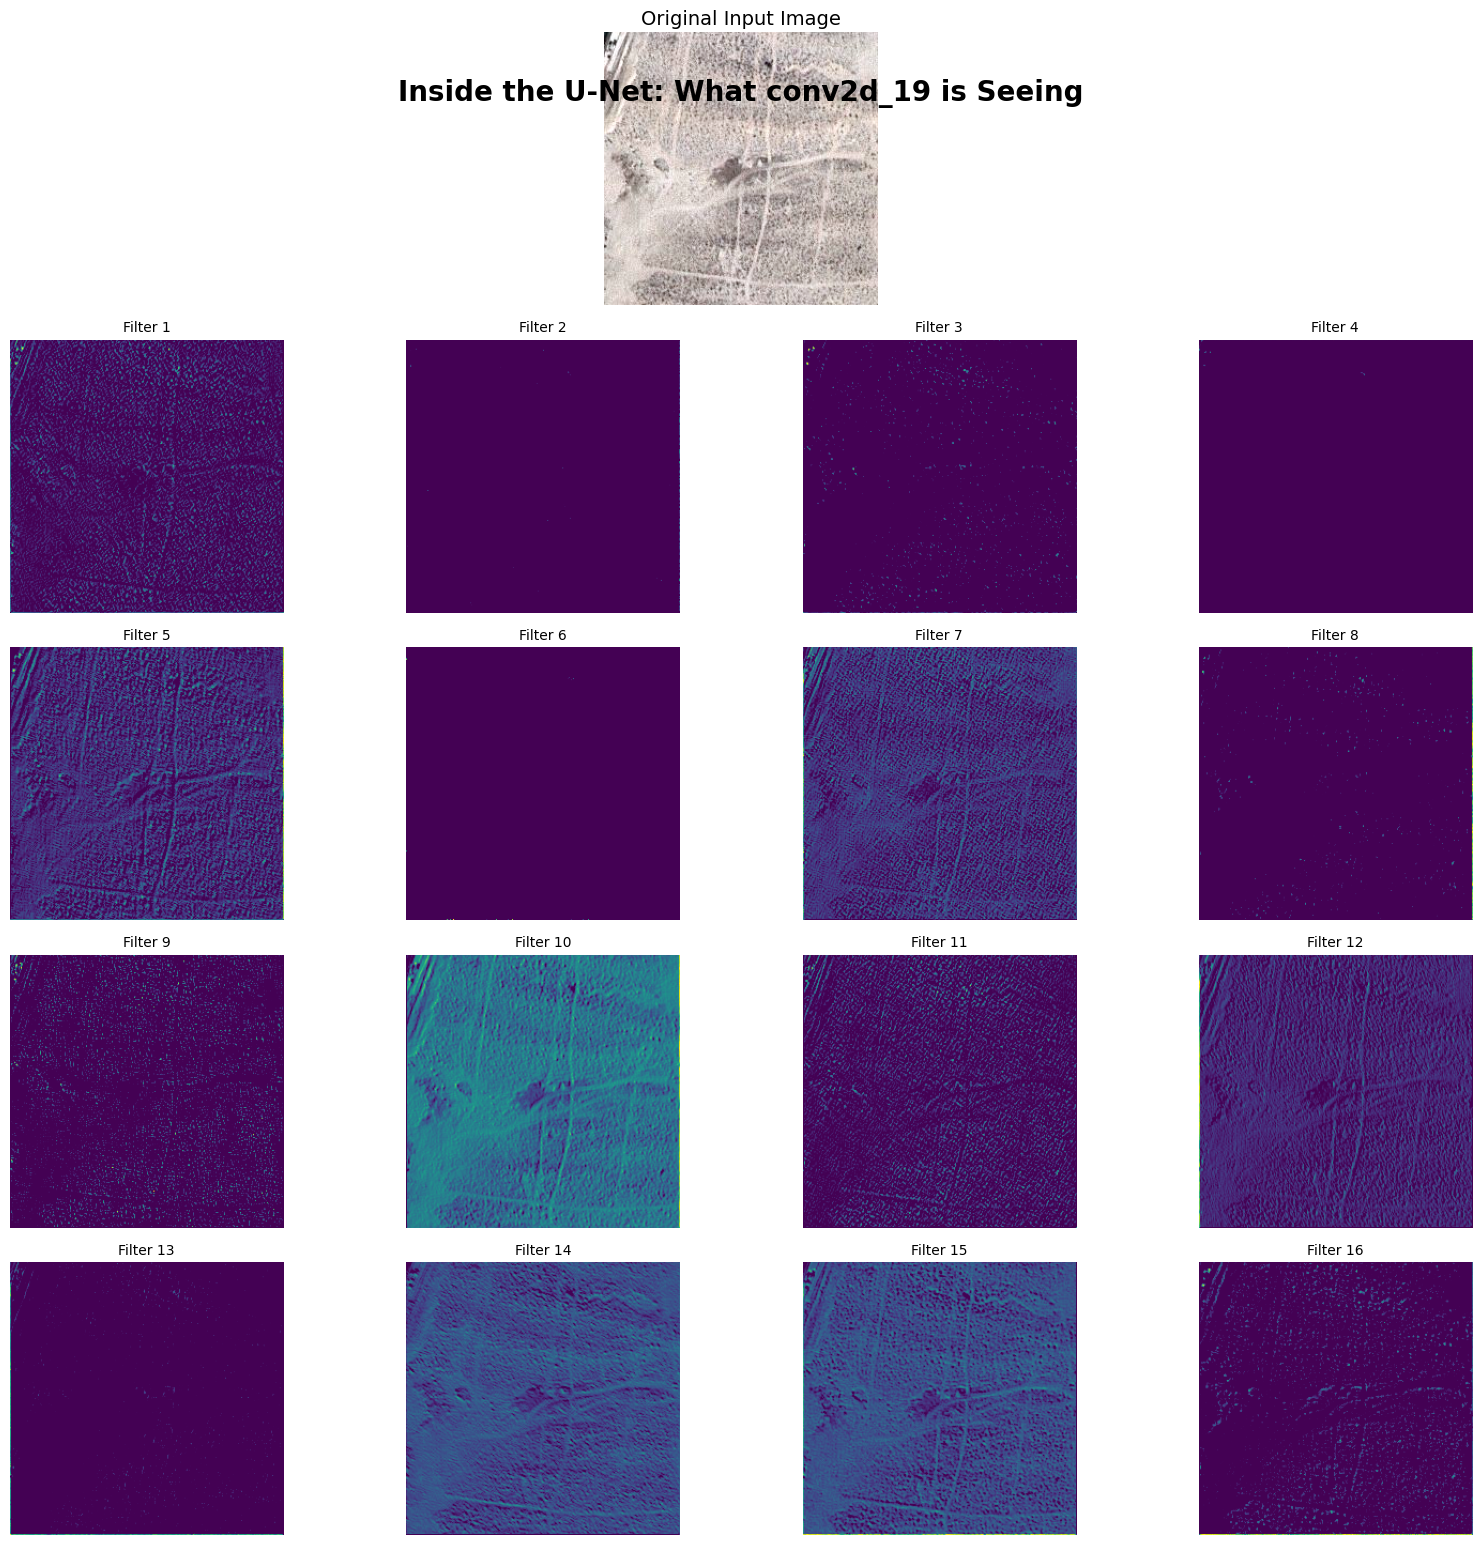

Execution complete. Check your system RAM!


In [ ]:
import tensorflow as tf
import matplotlib.pyplot as plt
import numpy as np
import random
import gc

# 1. Clear out the garbage to give the system a fighting chance
gc.collect()

print("Scanning model architecture for Convolutional Layers...")

# 2. Dynamically locate the first Conv2D layer in your U-Net
conv_layers = [layer.name for layer in model.layers if 'conv2d' in layer.name.lower()]

if not conv_layers:
    print("Could not locate a standard Conv2D layer. The architecture might be heavily customized.")
else:
    # We will target the very first convolutional layer to see the initial edge detection
    target_layer_name = conv_layers[0]
    print(f"Target locked on: {target_layer_name}. Extracting intermediate tensors...")

    # 3. Create a temporary sub-model that outputs exactly at this middle layer.
    # Warning: This instantiates a new Keras graph in memory!
    feature_extractor = tf.keras.Model(inputs=model.inputs, outputs=model.get_layer(target_layer_name).output)

    # 4. Grab a random image from the test set
    test_img = X_test[random.randint(0, len(X_test) - 1)]
    test_img_input = np.expand_dims(test_img, 0)

    # 5. Push the image through to get the hidden feature maps
    # THIS is where the RAM spikes!
    feature_maps = feature_extractor.predict(test_img_input, verbose=0)

    print(f"Feature Map Shape extracted: {feature_maps.shape}")
    print("Rendering visuals...")

    # 6. Plot the first 16 filters (channels) of what the AI is currently "seeing"
    plt.figure(figsize=(16, 16))
    plt.suptitle(f"Inside the U-Net: What {target_layer_name} is Seeing", fontsize=20, y=0.92, fontweight='bold')

    # Display the original image in the top center for reference
    plt.subplot(5, 4, (1, 4))
    plt.title("Original Input Image", fontsize=14)
    plt.imshow(test_img)
    plt.axis('off')

    # Display up to 16 individual activation filters
    for i in range(16):
        # We start the subplot index at 5 because the original image takes up the top row
        plt.subplot(5, 4, i + 5)

        # Check if the layer actually has 16 filters to avoid an index error
        if i < feature_maps.shape[-1]:
            # We plot the raw activations using the 'viridis' colormap
            # Bright yellow = strong activation (the model is highly interested in this pixel)
            # Dark purple = weak activation (the model is ignoring this pixel)
            plt.imshow(feature_maps[0, :, :, i], cmap='viridis')
            plt.title(f"Filter {i+1}", fontsize=10)
            plt.axis('off')

    plt.tight_layout()
    plt.show()

    print("Execution complete. Check your system RAM!")